---
title: "Methanol synthesis from CO2: does the printed kinetic model reproduce its own reactor simulations (Vanden Bussche and Froment)"
description: "Eq. 3, Table 2 and the printed equilibrium constants of Vanden Bussche and Froment (1996) put back against the paper's own adiabatic bench-reactor simulations and its Klier comparison, with the printed statistics rechecked."
categories: [sec:C, struct:S2, tier:T1, data:tier2]
date: 2026-11-27
---

# Methanol synthesis from CO2 (Vanden Bussche and Froment, 1996)

**Catalog ID:** `C2.5` · **Structures:** `S2` · **Tier:** T1

Vanden Bussche and Froment make CO2 the only carbon source of methanol on
Cu/ZnO/Al2O3: CO enters only through the reverse water gas shift. Their rate
equations (eq. 3), with the parameters of Table 2 and two equilibrium
constants, are among the most used methanol kinetics. The 276 experiments they
were fitted to are not printed, so this page cannot refit them. It asks a
narrower question the paper does allow: do the printed equations and numbers
reproduce the paper's own simulations, the adiabatic bench reactor of Figs. 5
to 7 and the Klier comparison of Fig. 8, at the conditions the paper states?
pymrm solves the plug-flow reactors; the printed statistics are rechecked on
the way.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "C2.5-vandenbussche-froment-methanol-co2-route"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from scipy import stats
from scipy.optimize import minimize_scalar
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from pymrm.checks import find_roots, observed_orders
from model import (ATOMS, NU, R_GAS, Kinetics, PlugFlowBed, Thermo, adiabatic_equilibrium,
                   equilibrium, half_units, reference_solution, table1_to_table2, table2)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])


def show(df, uuid, fmt=None):
    """Display a table with a pinned id, so two runs print the same HTML."""
    styler = df.style.hide(axis="index")
    if fmt:
        styler = styler.format(fmt)
    display(HTML(styler.set_uuid(uuid).to_html()))


def one_root(f, lo, hi, what, n_scan=64):
    """The single root of ``f`` on ``[lo, hi]`` (``find_roots``); raises unless exactly one."""
    res = find_roots(f, lo, hi, n_scan=n_scan, xtol=1e-13)
    if len(res["roots"]) != 1:
        raise ValueError(f"{what}: {len(res['roots'])} roots on [{lo}, {hi}]")
    return res["roots"][0]


def bounded_min(f, lo, hi, n_scan=61, xtol=1e-7, at_end_ok=False):
    """Minimum of ``f`` on ``[lo, hi]``: a scan of the whole window, then bounded refinement
    between the neighbours of the best scan point. When the best point is a window end the
    minimum is at or beyond it: raises, or with ``at_end_ok`` returns that end."""
    xs = np.linspace(lo, hi, n_scan)
    fs = np.array([f(x) for x in xs])
    i = int(np.nanargmin(fs))
    if i in (0, n_scan - 1):
        if at_end_ok:
            return float(xs[i]), float(fs[i])
        raise ValueError(f"minimum at the end of [{lo}, {hi}]")
    opt = minimize_scalar(f, bounds=(xs[i - 1], xs[i + 1]), method="bounded",
                          options={"xatol": xtol})
    return float(opt.x), float(opt.fun)

## Background

Industrial methanol is made from synthesis gas, CO, CO2 and H2, on a
Cu/ZnO/Al2O3 catalyst at 200 to 300 °C and 50 to 100 bar. Which carbon oxide
the methanol comes from was argued over for decades. Vanden Bussche and
Froment (J. Catal. 161, 1-10, 1996) built a mechanism in which CO2 is
hydrogenated to methanol and CO only exchanges oxygen with CO2 through the
water gas shift, fitted it to 276 experiments (180 to 280 °C, 15 to 51 bar),
and showed what it predicts: an adiabatic bench reactor (Table 3, Figs. 5 to
7) and the maximum in methanol yield against CO2 content that Klier et al.
measured (Fig. 8).

The experiments are not in the paper (footnote 3, p. 5, offers them on
request), and Figs. 3 and 4 are parity plots without conditions. What is
printed is the model and the authors' own simulations with it. Those
simulations are the test here: the page computes them from the printed
equations and parameters and compares. They are the authors' calculations,
not measurements, so agreement tests the transcription and the unstated
inputs, not the chemistry. The printed statistics (Table 1, p. 7) are
rechecked from their own digits.

## The published model

Two overall reactions (p. 5): methanol from CO2, CO2 + 3 H2 = CH3OH + H2O, and
the reverse water gas shift (RWGS), CO2 + H2 = CO + H2O. Eq. 3 (p. 6), with
partial pressures $p_i$ in bar and rates in mol/(kg$_\mathrm{cat}$ s):

$$r_\mathrm{MeOH} = \frac{k'_{5a}K'_2K_3K_4K_{H_2}\,p_{CO_2}p_{H_2}\left[1 - \frac{1}{K_1^*}\frac{p_{H_2O}p_{CH_3OH}}{p_{H_2}^3p_{CO_2}}\right]}{D^3},\qquad
r_\mathrm{RWGS} = \frac{k'_1\,p_{CO_2}\left[1 - K_3^*\frac{p_{H_2O}p_{CO}}{p_{CO_2}p_{H_2}}\right]}{D},$$

$$D = 1 + \frac{K_{H_2O}}{K_8K_9K_{H_2}}\frac{p_{H_2O}}{p_{H_2}} + \sqrt{K_{H_2}p_{H_2}} + K_{H_2O}p_{H_2O}.$$

Each group is $\kappa = A\exp(B/(RT))$ (Table 2). The equilibrium constants
are taken from Graaf et al. (p. 5): $\log_{10}K_1^* = 3066/T - 10.592$
(bar$^{-2}$; printed lower case $k_1^*$ there and $K^*$ in eq. 3) and
$\log_{10}(1/K_3^*) = -2073/T + 2.029$, where $K_3^*$ is the water gas shift
constant. The bench reactor of Table 3 is an adiabatic, isobaric plug flow:

$$\frac{dF_i}{dW} = \sum_j \nu_{ij} r_j,\qquad \Big(\sum_i F_iC_{p,i}\Big)\frac{dT}{dW} = \sum_j(-\Delta H_j)\,r_j.$$

| symbol | code | meaning |
|---|---|---|
| $\sqrt{K_{H_2}}$, $K_{H_2O}$ | `sqrtKH2`, `KH2O` | adsorption groups (bar$^{-1/2}$, bar$^{-1}$) |
| $K_{H_2O}/(K_8K_9K_{H_2})$ | `Kw` | dimensionless group, no B |
| $k'_{5a}K'_2K_3K_4K_{H_2}$, $k'_1$ | `k5`, `k1` | rate groups, mol/(kg s bar$^2$), mol/(kg s bar) |
| $K_1^*$, $K_3^*$ | `K1`, `K3` | equilibrium constants |
| $\zeta = z/L = W/W_\mathrm{bed}$ | `zeta` | reduced axial position (the catalyst is uniform along the tube) |
| $F$ | `factor` | a factor on both rates (1 as printed) |

## Parameters and assumptions

Tables 1 to 3 and the other printed numbers are read from CSVs as text, so
every printed entry keeps its precision. Assumptions, each where the paper is
silent:

- **Gas constant** $R$ = 8.314462618 J/(mol K). It is not printed; Table 1
  converts to Table 2 only for $R$ between 8.31413 and 8.31463 (Results, R1),
  and B is in J/mol.
- **Ideal gas** (the paper reports SRK compressibility factors 0.99 to 1.01 in
  its window, p. 5), isobaric bed (no pressure drop is printed).
- **Inert**: Table 3 does not name it. Argon, the internal standard of the
  experiments (p. 2), is the page's reading; nitrogen is computed beside it.
- **Heats and heat capacities** are not printed. The page reads the heats as the
  298.15 K standard heats from formation enthalpies (NIST WebBook; methanol
  from its liquid value and heat of vaporisation) and $C_{p,i}(T)$ from the
  NIST WebBook (Shomate coefficients of Chase 1998; methanol from the TRC
  ideal-gas table by a cubic spline). The van 't Hoff heats of the two
  equilibrium correlations are computed beside it. Fig. 5's plateau selects
  between them (R3).
- The bed is uniform: $\zeta = z/L = W/W_\mathrm{bed}$ with $W_\mathrm{bed}$ =
  34.8 g over the 0.15 m tube.

In [3]:
T1 = load_data("vandenbussche-1996-table1.csv", page=PAGE, dtype=str)
T2 = load_data("vandenbussche-1996-table2.csv", page=PAGE, dtype=str)
T3 = load_data("vandenbussche-1996-table3.csv", page=PAGE, dtype=str).set_index("quantity")
PN = load_data("vandenbussche-1996-printed-numbers.csv", page=PAGE, dtype=str).set_index("name")
SHOMATE = load_data("nist-webbook-thermo.csv", page=PAGE, dtype=str)
MEOH_CP = load_data("nist-webbook-methanol-cp.csv", page=PAGE, dtype=str)
MEOH_H = load_data("nist-webbook-methanol-enthalpy.csv", page=PAGE, dtype=str).set_index("quantity")

PAR = table2(T2)                                              # Table 2, A and B (J/mol)
EQ = {"K1_slope": float(PN.value_printed["log10_K1star_slope"]),          # p. 5
      "K1_icpt": float(PN.value_printed["log10_K1star_intercept"]),
      "K3inv_slope": float(PN.value_printed["log10_invK3star_slope"]),
      "K3inv_icpt": float(PN.value_printed["log10_invK3star_intercept"])}
T_AV = float(PN.value_printed["T_av"])                        # K, Table 1 reference temperature
N_EXP = int(PN.value_printed["n_experiments"])                # 276 experiments, two responses each
T3v = {k: float(v) for k, v in T3.value_printed.items()}
W_BED = 1e-3 * T3v["catalyst mass"]                            # kg
M_FLOW = 1e-5 * T3v["mass flow m"]                             # kg/s
T0_BED, P_BED = T3v["inlet temperature T0"], T3v["inlet total pressure p_t0"]   # K, bar
Y_FEED = 0.01 * np.array([T3v[f"feed {s}"] for s in ("CO", "CO2", "H2", "MeOH", "H2O", "inert")])
L_TUBE, D_TUBE, RHO_S = T3v["reactor length"], T3v["reactor diameter"], T3v["catalyst density"]
DHF_MEOH = 1e3 * (float(MEOH_H.value_kJ_per_mol["dHf_liquid"])
                  + float(MEOH_H.value_kJ_per_mol["dH_vap"]))    # J/mol, gaseous methanol
DHF_MEOH_U = 1e3 * (float(MEOH_H.uncertainty_kJ_per_mol["dHf_liquid"])
                    + float(MEOH_H.uncertainty_kJ_per_mol["dH_vap"]))
CP_TEST = 3350.0   # J/(kg K): constant c_p of the check values' test model E0 (check_values.meta.yaml)


def kinetics(par=PAR, **kw):
    return Kinetics(par, equil=kw.pop("equil", EQ), **kw)


def thermo(heats="H298", inert="Ar", cp_scale=1.0, cp_mass=None, dhf=DHF_MEOH):
    return Thermo(SHOMATE, MEOH_CP, inert=inert, heats=heats, cp_scale=cp_scale,
                  cp_mass=cp_mass, dhf_meoh=dhf)


def w_over_f0(th, y=Y_FEED, m=M_FLOW, w=W_BED):
    """W/F0 of the bench bed (kg s/mol): F0 from the mass flow and the feed's molar mass."""
    return w / (m / th.m_feed_of(y))


TH = thermo()
show(pd.DataFrame({"reading": ["298 K heats (page)", "van 't Hoff heats"],
                   "dH_MeOH (kJ/mol)": [TH.dH[0] / 1e3, thermo("HvH").dH[0] / 1e3],
                   "dH_RWGS (kJ/mol)": [TH.dH[1] / 1e3, thermo("HvH").dH[1] / 1e3]}),
     "c25p1", {"dH_MeOH (kJ/mol)": "{:.3f}", "dH_RWGS (kJ/mol)": "{:.3f}"})
print(cite_data(load_meta("vandenbussche-1996-table2.csv", page=PAGE)))
print(cite_data(load_meta("nist-webbook-thermo.csv", page=PAGE)))

reading,dH_MeOH (kJ/mol),dH_RWGS (kJ/mol)
298 K heats (page),-50.204,41.169
van 't Hoff heats,-58.698,39.687


Vanden Bussche, K. M.; Froment, G. F. (1996) — Journal of Catalysis 161, 1-10 — doi:10.1006/jcat.1996.0156 — table
Linstrom, P. J.; Mallard, W. G. (eds.) (2026) — NIST Chemistry WebBook, NIST Standard Reference Database Number 69 — repository


## The data

- `vandenbussche-1996-table1.csv`, `-table2.csv`, `-table3.csv`,
  `-printed-numbers.csv`: the tables and the printed numbers of the text
  (vector text in the PDF; every entry checked against the page image).
- `vandenbussche-1996-fig5b.csv` (the temperature trace of Fig. 5b),
  `-fig8.csv` (the simulated curve of Fig. 8) and `-figure-readings.csv`
  (plateaus of Figs. 5 to 7, the 15-bar CO2 minimum of Fig. 6c, Klier's
  markers at 2 % CO2 in Fig. 8): digitised by `extract_figures.py` from the
  1-bit scans embedded in the PDF, at native resolution, calibrated on the
  tick marks (the axis value of one pixel is printed below). The inlet ends of
  Fig. 7a are not read: the five curves merge there.
- `nist-webbook-*.csv`: heat capacities and formation enthalpies (not from the
  paper).
- `check_values.csv`: 53 values of the page's functions at one test
  condition, computed by a second, independent script (sidecar).

Every figure is a simulation by the authors. Nothing here is a measurement
except Klier's markers in Fig. 8, which the page does not fit.

In [4]:
F5B = load_data("vandenbussche-1996-fig5b.csv", page=PAGE)
F8 = load_data("vandenbussche-1996-fig8.csv", page=PAGE)
READ = load_data("vandenbussche-1996-figure-readings.csv", page=PAGE)
RD = {(r.figure, r.curve, r.quantity): r.value for r in READ.itertuples()}
PX = {f: float(READ.value_per_px[READ.figure == f].iloc[0]) for f in ("5b", "8")}   # per pixel
print(cite_data(load_meta("vandenbussche-1996-fig5b.csv", page=PAGE)))
_px = READ.groupby("figure").value_per_px.first()
print("one pixel: " + ", ".join(f"Fig. {f}: {v:.4g} {READ.unit[READ.figure == f].iloc[0]}"
                                for f, v in _px.items()))
show(READ[["figure", "curve", "quantity", "value", "sd", "n_px", "value_per_px"]], "c25d1",
     {"value": "{:.4f}", "sd": "{:.4f}", "value_per_px": "{:.4f}"})

Vanden Bussche, K. M.; Froment, G. F. (1996) — Journal of Catalysis 161, 1-10 — doi:10.1006/jcat.1996.0156 — digitised from Fig. 5b, journal page 8 (embedded 1-bit scan, 307 ppi)
one pixel: Fig. 5a: 0.01158 mol%, Fig. 5b: 0.1773 K, Fig. 6a: 0.00701 mol%, Fig. 6b: 0.2 K, Fig. 6c: 0.00307 mol%, Fig. 7a: 0.3333 C, Fig. 7b: 0.00723 mol%, Fig. 8: 0.08889 %


figure,curve,quantity,value,sd,n_px,value_per_px
5a,CO,y_molpct,2.8732,0.0014,182,0.0116
5a,MeOH,y_molpct,2.3526,0.0000,182,0.0116
5a,CO2,y_molpct,2.0664,0.0031,150,0.0116
5a,H2O,y_molpct,1.0484,0.0029,146,0.0116
5b,base,T_K,550.5922,0.0407,329,0.1773
6a,50 bar,y_MeOH_molpct,2.3484,0.0023,70,0.0070
6a,30 bar,y_MeOH_molpct,1.7358,0.0025,107,0.0070
6a,15 bar,y_MeOH_molpct,1.0425,0.0005,142,0.0070
6b,50 bar,T_K,550.6038,0.0434,79,0.2000
6b,30 bar,T_K,535.4833,0.0714,108,0.2000


## PyMRM implementation

`model.py` holds the kinetics (`Kinetics`), the thermodynamics (`Thermo`) and
the reactor (`PlugFlowBed`). The bed is a steady finite-volume problem in the
reduced catalyst mass $\zeta$: seven fields per cell, the six molar flows over
the feed flow $F_i/F_0$ and $T/T_0$, convected with unit velocity by
`construct_convflux_upwind` and `construct_div` (assembled once), the source
$s(u)$ from eq. 3 and the energy balance with a `NumJac` Jacobian (7 x 7 block
per cell), solved by `newton` with lower bounds on the flows and checked by
`residual_check`. The inlet is a Dirichlet face (outward normal $-\zeta$:
$u = u_\mathrm{in}$), the outlet `{"outflow": True}`, read with
`compute_boundary_values`. First-order upwind; values between cells are read
linearly between centres, and quoted values are Richardson-extrapolated from
two grids. An isothermal bed (Fig. 8) is the same class without the energy
balance. The second route is `scipy.integrate.solve_ivp` (Radau) on the same
source function.

The rates are written with the approach terms multiplied out, so they are
smooth and exactly zero at $p_{CO_2} = p_{H_2O} = 0$. Because the bed equations
contain the catalyst mass only through $W r$, a factor $F$ on both rates is the
same as a bed $F$ times longer: the profile with factor $F$ at $\zeta$ is the
profile with factor 1 at $F\zeta$. The page solves one bed twice as long as
Table 3's and reads every $F$ from it (cross-checked below against a
direct solve).

Before any result, the page's functions reproduce all 53 check values of the
independent script (rates and constants at a test condition, Table 1 to 2,
statistics, two equilibria, an isothermal bed, and the bench bed with the
script's test energy model: constant $c_p$ = 3350 J/(kg K), van 't Hoff heats,
argon).

In [5]:
TC = {"T": 523.15, "p": 50.0, "y": np.array([0.030, 0.025, 0.800, 0.010, 0.005, 0.130])}
X8 = 3.0                                                  # % CO2 of the PF8 and EQ8 rows


def fig8_feed(x):
    """Fig. 8 caption: x % CO2, (30 - x) % CO, 70 % H2."""
    return np.array([(30.0 - x) / 100.0, x / 100.0, 0.70, 0.0, 0.0, 0.0])


def check_values():
    kin = kinetics()
    p = TC["p"] * TC["y"]
    c = kin.constants(TC["T"])
    terms = kin.denominator_terms(p, TC["T"])
    ap, r = kin.approach(p, TC["T"]), kin.rates(p, TC["T"])
    hvh = thermo("HvH", cp_mass=CP_TEST)
    out = {"TC_sqrtKH2": c["sqrtKH2"], "TC_KH2O": c["KH2O"], "TC_k5lump": c["k5"],
           "TC_k1": c["k1"], "TC_K1star": c["K1"], "TC_K3star": c["K3"],
           "TC_den": terms.sum(), "TC_beta": 1.0 / terms.sum(),
           "TC_approach_MeOH": ap[0], "TC_approach_RWGS": ap[1],
           "TC_r_MeOH": r[0], "TC_r_RWGS": r[1],
           "TC_dH1_vantHoff": hvh.dH[0], "TC_dH2_vantHoff": hvh.dH[1]}
    t1 = T1.set_index(["group", "param"])
    for key, g in (("sqrtKH2", "sqrt(K_H2)"), ("KH2O", "K_H2O"), ("k5", "k'5a K'2 K3 K4 K_H2"),
                   ("k1", "k'1")):
        out[f"T1_A_from_Astar_{key}"] = table1_to_table2(
            float(t1.value[(g, "A*")]), float(t1.value[(g, "B")]), R_GAS, T_AV)
    s = stats_r1()
    out.update({"T1_R_window_KH2O_lo": s["R_lo"], "T1_R_window_KH2O_hi": s["R_hi"],
                "T1_t975_dof543": s["t975"], "T1_dof": s["dof"],
                "T1_ci_multiplier_k5B": s["mult"], "T1_ci_multiplier_k5B_lo": s["mult_lo"],
                "T1_ci_multiplier_k5B_hi": s["mult_hi"],
                "T1_sd_from_t_sqrtKH2A": s["sd_t"], "T1_sd_from_t_sqrtKH2A_lo": s["sd_t_lo"],
                "T1_sd_from_t_sqrtKH2A_hi": s["sd_t_hi"],
                "T1_tA_max_k5": s["tmax"]["k5"], "T1_tA_max_KH2O": s["tmax"]["KH2O"],
                "T1_tA_min_sqrtKH2": s["tmin"]["sqrtKH2"], "T1_tA_min_k1": s["tmin"]["k1"],
                "T1_tA_zero_corr_k5": s["t0"]["k5"],
                "ST_minus_dS_H2_from_T2": s["dS_H2_T2"], "ST_minus_dS_H2O_from_T2": s["dS_H2O_T2"],
                "ST_minus_dS_H2_from_T1": s["dS_H2_T1"], "ST_bed_voidage_implied": s["voidage"]})
    out["ST_feed_molar_mass_Ar"] = hvh.m_feed_of(Y_FEED)
    out["ST_F0_Ar"] = M_FLOW / hvh.m_feed_of(Y_FEED)
    y8 = fig8_feed(X8)
    for T, tag in ((523.15, "523K"), (498.15, "498K")):
        out[f"EQ8_Xeq_x3_{tag}"] = equilibrium(kin, y8, T, 75.0)["a"] / 0.30
    out["EQ8_RWGS_extent_x3_523K"] = equilibrium(kin, y8, 523.15, 75.0)["b"]
    bed8 = PlugFlowBed(kin, y8, 503.15, 75.0, 10.0)
    u8 = reference_solution(bed8).y[:, -1]
    out["PF8_X_x3_503K_tau10"] = u8[3] / 0.30
    out["PF8_yCO_x3_503K_tau10"] = u8[0] / u8[:6].sum()
    eq = adiabatic_equilibrium(kin, hvh, Y_FEED, T0_BED, P_BED)
    out.update({"AD_Teq_plateau": eq["T"], "AD_yMeOH_eq": eq["y"][3], "AD_yCO_eq": eq["y"][0]})
    bed = PlugFlowBed(kin, Y_FEED, T0_BED, P_BED, w_over_f0(hvh), thermo=hvh)
    sol = reference_solution(bed)
    out["AD_Tout_W34p8g"] = T0_BED * sol.y[6, -1]
    out["AD_yMeOH_out"] = sol.y[3, -1] / sol.y[:6, -1].sum()
    out["AD_zL_RWGS_reversal"] = one_root(
        lambda z: bed.rates_at(sol.sol(z)[None, :])[0, 1], 1e-4, 0.5, "RWGS reversal")
    out["AD_zL_T_half_rise"] = one_root(
        lambda z: T0_BED * sol.sol(z)[6] - 0.5 * (T0_BED + eq["T"]), 1e-4, 1.0, "half rise")
    u01 = sol.sol(0.1)
    out["AD_T_at_zL0p1"] = T0_BED * u01[6]
    out["AD_yMeOH_at_zL0p1"] = u01[3] / u01[:6].sum()
    return out


def stats_r1(t1=T1, t2=T2, r_gas=R_GAS, t_av=T_AV, n_exp=N_EXP, quantile="t"):
    """Table 1 and its printed statistics, from the printed digits only (closed forms)."""
    t1 = t1.set_index(["group", "param"])
    t2 = t2.set_index(["group", "param"])
    groups = {"sqrtKH2": "sqrt(K_H2)", "KH2O": "K_H2O", "k5": "k'5a K'2 K3 K4 K_H2",
              "k1": "k'1"}
    f = lambda g, p, col="value": float(t1.loc[(g, p), col])     # noqa: E731
    s = {"hu": {}, "tmax": {}, "tmin": {}, "t0": {}}
    for key, g in groups.items():
        a_t1 = table1_to_table2(f(g, "A*"), f(g, "B"), r_gas, t_av)
        s["hu"][key] = half_units(t2.value_printed[(g, "A")], a_t1)
        rel_a = f(g, "A*", "std_dev") / f(g, "A*")              # sd(ln A*)
        rel_b = f(g, "B", "std_dev") / (r_gas * t_av)           # sd(B)/(R T_av)
        s["tmax"][key] = 1.0 / abs(rel_b - rel_a)               # any correlation
        s["tmin"][key] = 1.0 / (rel_b + rel_a)
        s["t0"][key] = 1.0 / np.hypot(rel_a, rel_b)
    # gas-constant window from K_H2O over every corner of the rounding box
    g = groups["KH2O"]
    corners = [f(g, "B") + db for db in (-0.5, 0.5)]
    a_star = [f(g, "A*") + da for da in (-0.005, 0.005)]
    a_pr = [float(t2.value_printed[(g, "A")]) + da for da in (-0.005e-11, 0.005e-11)]
    rs = [b / (t_av * (np.log(ast) - np.log(ap))) for b in corners for ast in a_star for ap in a_pr]
    s["R_lo"], s["R_hi"] = min(rs), max(rs)
    n_par = int(t1.value.notna().sum())                         # printed estimates
    s["dof"] = 2 * n_exp - n_par
    s["t975"] = float(stats.t.ppf(0.975, s["dof"]) if quantile == "t" else stats.norm.ppf(0.975))
    g = groups["k5"]
    lo, hi, sd = f(g, "B", "lower_95"), f(g, "B", "upper_95"), f(g, "B", "std_dev")
    s["mult"] = (hi - lo) / 2.0 / sd
    s["mult_lo"] = (hi - lo - 1.0) / 2.0 / (sd + 0.05)
    s["mult_hi"] = (hi - lo + 1.0) / 2.0 / (sd - 0.05)
    g = groups["sqrtKH2"]
    v, t = f(g, "A*"), f(g, "A*", "t_value")
    s["sd_t"], s["sd_t_lo"], s["sd_t_hi"] = v / t, (v - 0.005) / (t + 0.005), (v + 0.005) / (t - 0.005)
    s["sd_printed"] = f(g, "A*", "std_dev")
    a_h2 = float(t2.value_printed[(groups["sqrtKH2"], "A")])
    a_h2o = float(t2.value_printed[(groups["KH2O"], "A")])
    s["dS_H2_T2"] = -2.0 * r_gas * np.log(a_h2)
    s["dS_H2O_T2"] = -r_gas * np.log(a_h2o)
    s["dS_H2_T1"] = -2.0 * r_gas * np.log(table1_to_table2(f(g, "A*"), f(g, "B"), r_gas, t_av))
    s["voidage"] = 1.0 - W_BED / (RHO_S * np.pi / 4.0 * D_TUBE ** 2 * L_TUBE)
    return s


CHECK = check_values()
dev = assert_check_values(CHECK, page=PAGE)
print(f"{len(dev)} check values reproduced; largest relative deviation "
      f"{max(abs(v) for v in dev.values()):.1e}")

check values: 53 of 53 agree, worst relative -4.4e-12
53 check values reproduced; largest relative deviation 4.4e-12


## Results

### R1. The printed constants and statistics

Table 2 is Table 1 converted with $A = A^*\exp(-B/(RT_\mathrm{av}))$,
$T_\mathrm{av}$ = 501.57 K. Each converted value is compared with the
printed one in half-units of its last printed digit. The statistics of p. 7
are rechecked from Table 1's own digits: the degrees of freedom, the
multiplier of the printed intervals, the standard deviations, and the claim
(p. 7) that "all parameters stay significantly different from 0 with a 95%
probability, except for the frequency factor of the water adsorption
constant." That claim concerns the back-transformed frequency factors $A$,
whose standard deviation needs the unprinted correlation of $A^*$ and $B$; the
page bounds it over every correlation (delta method:
$t(A) = 1/\mathrm{sd}(\ln A)$, with
$|s_B/(RT_\mathrm{av}) - s_{A^*}/A^*| \le \mathrm{sd}(\ln A) \le s_B/(RT_\mathrm{av}) + s_{A^*}/A^*$).

In [6]:
def study_r1(**kw):
    s = stats_r1(**kw)
    m = {"r1_hu": np.array(list(s["hu"].values())), "r1_hu_KH2O": s["hu"]["KH2O"],
         "r1_R_lo": s["R_lo"], "r1_R_hi": s["R_hi"], "r1_dof": s["dof"], "r1_t975": s["t975"],
         "r1_multiplier": s["mult"], "r1_t975_above_window": s["t975"] - s["mult_hi"],
         "r1_sd_gap": s["sd_t_lo"] - s["sd_printed"],
         "r1_tA_max": np.array(list(s["tmax"].values())),
         "r1_tA_max_k5": s["tmax"]["k5"], "r1_tA_max_KH2O": s["tmax"]["KH2O"],
         "r1_tA_min_sqrtKH2": s["tmin"]["sqrtKH2"], "r1_tA_min_k1": s["tmin"]["k1"],
         "r1_dS_H2_T2": s["dS_H2_T2"],
         "r1_dS_H2_T2_hu": half_units(PN.value_printed["minus_dS_ads_H2"], s["dS_H2_T2"]),
         "r1_dS_H2_T1_hu": half_units(PN.value_printed["minus_dS_ads_H2"], s["dS_H2_T1"]),
         "r1_dS_H2O_hu": half_units(PN.value_printed["minus_dS_ads_H2O"], s["dS_H2O_T2"]),
         "r1_voidage": s["voidage"]}
    m["r1_groups_outside_rounding"] = int(np.sum(m["r1_hu"] > 1.0))
    m["r1_A_not_significant"] = int(np.sum(m["r1_tA_max"] < 1.96))
    return m


R1 = study_r1()
R1_8314 = study_r1(r_gas=8.314)
show(pd.DataFrame({"group": ["sqrt(K_H2)", "K_H2O", "k5 lump", "k'1"],
                   "half-units, R = 8.314462618": R1["r1_hu"],
                   "half-units, R = 8.314": R1_8314["r1_hu"],
                   "t(A), largest over correlation": R1["r1_tA_max"]}), "c25r1",
     {"half-units, R = 8.314462618": "{:.3f}", "half-units, R = 8.314": "{:.3f}",
      "t(A), largest over correlation": "{:.3f}"})
display(Markdown(
    f"With $R$ = 8.314462618 J/(mol K), {4 - R1['r1_groups_outside_rounding']} of 4 converted "
    f"frequency factors round to Table 2 (largest {R1['r1_hu'].max():.2f} half-units). With "
    f"$R$ = 8.314, $K_{{H_2O}}$ misses by {R1_8314['r1_hu_KH2O']:.2f} half-units; its rounding box "
    f"allows only $R$ = {R1['r1_R_lo']:.5f} to {R1['r1_R_hi']:.5f}. The degrees of freedom are "
    f"2 x {N_EXP} - 9 = {R1['r1_dof']}, as printed (p. 7: \"The tabulated $t_{{0.95}}$, with 543 "
    f"degrees of freedom, amounts to 1.96.\"), but $t_{{0.975}}({R1['r1_dof']})$ = "
    f"{R1['r1_t975']:.4f}; the intervals of Table 1 use {R1['r1_multiplier']:.5f} (the $k_5$-lump "
    f"$B$ row), and the rounding of its limits and standard deviation keeps the multiplier "
    f"{R1['r1_t975_above_window']:.4f} below $t(543)$: the intervals are normal-quantile intervals "
    f"(a 0.2 % difference, stated, not corrected). The column headed \"$t_{{0.95}}$ value\" is "
    f"value/sd. For $A^*$ of $\\sqrt{{K_{{H_2}}}}$ value/t gives a standard deviation whose rounding "
    f"window lies {R1['r1_sd_gap']:.1e} above the printed 0.375: a last-digit slip.\n\n"
    f"Back-transformed, the frequency factor of the $k_5$ lump has $t(A)$ at most "
    f"{R1['r1_tA_max_k5']:.3f} for any correlation, and $K_{{H_2O}}$ at most "
    f"{R1['r1_tA_max_KH2O']:.3f}; $\\sqrt{{K_{{H_2}}}}$ and $k'_1$ have at least "
    f"{R1['r1_tA_min_sqrtKH2']:.3f} and {R1['r1_tA_min_k1']:.3f}. So {R1['r1_A_not_significant']} "
    f"of 4 frequency factors are not significant at 1.96 whatever the correlation: the paper's "
    f"exception names only the water adsorption constant, the $k_5$ lump is a second one.\n\n"
    f"The entropy rule (p. 7): $-\\Delta S_{{ads}}$ of hydrogen from Table 2's rounded 0.499 is "
    f"{R1['r1_dS_H2_T2']:.4f} J/(mol K), {R1['r1_dS_H2_T2_hu']:.2f} half-units from the printed "
    f"11.56; from Table 1 it would be {R1['r1_dS_H2_T1_hu']:.2f} half-units away, so the printed "
    f"value comes from the rounded Table 2. Water: {R1['r1_dS_H2O_hu']:.2f} half-units from the "
    f"printed 195. Table 3's 34.8 g in the tube implies a bed voidage of {R1['r1_voidage']:.4f} "
    f"(the printed porosity 0.5 is per pellet)."))

group,"half-units, R = 8.314462618","half-units, R = 8.314","t(A), largest over correlation"
sqrt(K_H2),0.385,0.614,2.300
K_H2O,0.384,1.807,1.399
k5 lump,0.725,0.829,0.701
k'1,0.015,0.294,2.538


With $R$ = 8.314462618 J/(mol K), 4 of 4 converted frequency factors round to Table 2 (largest 0.72 half-units). With $R$ = 8.314, $K_{H_2O}$ misses by 1.81 half-units; its rounding box allows only $R$ = 8.31413 to 8.31463. The degrees of freedom are 2 x 276 - 9 = 543, as printed (p. 7: "The tabulated $t_{0.95}$, with 543 degrees of freedom, amounts to 1.96."), but $t_{0.975}(543)$ = 1.9643; the intervals of Table 1 use 1.96000 (the $k_5$-lump $B$ row), and the rounding of its limits and standard deviation keeps the multiplier 0.0042 below $t(543)$: the intervals are normal-quantile intervals (a 0.2 % difference, stated, not corrected). The column headed "$t_{0.95}$ value" is value/sd. For $A^*$ of $\sqrt{K_{H_2}}$ value/t gives a standard deviation whose rounding window lies 9.1e-04 above the printed 0.375: a last-digit slip.

Back-transformed, the frequency factor of the $k_5$ lump has $t(A)$ at most 0.701 for any correlation, and $K_{H_2O}$ at most 1.399; $\sqrt{K_{H_2}}$ and $k'_1$ have at least 2.178 and 2.390. So 2 of 4 frequency factors are not significant at 1.96 whatever the correlation: the paper's exception names only the water adsorption constant, the $k_5$ lump is a second one.

The entropy rule (p. 7): $-\Delta S_{ads}$ of hydrogen from Table 2's rounded 0.499 is 11.5596 J/(mol K), 0.08 half-units from the printed 11.56; from Table 1 it would be 1.20 half-units away, so the printed value comes from the rounded Table 2. Water: 0.25 half-units from the printed 195. Table 3's 34.8 g in the tube implies a bed voidage of 0.3499 (the printed porosity 0.5 is per pellet).

### R2. The rate law at one state

At the test condition TC (523.15 K, 50 bar, 3.0 % CO, 2.5 % CO2, 80 % H2,
1.0 % methanol, 0.5 % water) the rates and the four terms of $D$:

In [7]:
def study_r2(par=PAR, p_unit=1.0):
    kin = kinetics(par, p_unit=p_unit)
    p = TC["p"] * TC["y"]
    r = kin.rates(p, TC["T"])
    terms = kin.denominator_terms(p, TC["T"])
    return {"r2_r_MeOH": r[0], "r2_r_RWGS": r[1], "r2_share_sqrtKH2": terms[2] / terms.sum()}


R2 = study_r2()
display(Markdown(
    f"$r_\\mathrm{{MeOH}}$ = {R2['r2_r_MeOH']:.5f} and $r_\\mathrm{{RWGS}}$ = "
    f"{R2['r2_r_RWGS']:.5f} mol/(kg s); the hydrogen term $\\sqrt{{K_{{H_2}}p_{{H_2}}}}$ is "
    f"{100 * R2['r2_share_sqrtKH2']:.1f} % of $D$. Because $D$ is dominated by a term in "
    "$\\sqrt{p}$ and enters methanol cubed, pressures in kPa instead of bar in the kinetic groups "
    "would change the rates by large factors (a break row below)."))

$r_\mathrm{MeOH}$ = 0.01908 and $r_\mathrm{RWGS}$ = 0.00823 mol/(kg s); the hydrogen term $\sqrt{K_{H_2}p_{H_2}}$ is 72.2 % of $D$. Because $D$ is dominated by a term in $\sqrt{p}$ and enters methanol cubed, pressures in kPa instead of bar in the kinetic groups would change the rates by large factors (a break row below).

### R3. Fig. 5: the bench reactor of Table 3

Table 3: 34.8 g of catalyst, 2.8e-5 kg/s, 493.2 K, 50 bar, 4 % CO, 3 % CO2,
82 % H2, 11 % inert. The page solves the adiabatic bed for four readings of
the unprinted inputs, {298 K heats, van 't Hoff heats} x {argon, nitrogen},
with the rates as printed ($F$ = 1), and compares with the digitised Fig. 5b
(points at $z/L \ge$ 0.01). Then one factor $F$ on both rates per reading,
by bounded minimisation of the RMS against Fig. 5b. The text (p. 7) says: "At 3
mm into the bed the reverse water gas shift reaches its equilibrium value and
subsequently switches direction." and "At 3 cm in the bed, the thermodynamic
equilibrium concentrations are attained".

reading,plateau (K),plateau - Fig. 5b (K),RMS at F = 1 (K),fitted F,RMS at F (K)
"298 K heats, Ar (page)",550.921,0.328,1.431,1.096,0.308
"van 't Hoff, Ar",553.211,2.619,2.603,0.913,2.216
"298 K heats, N2",550.154,-0.438,4.922,1.363,0.421
"van 't Hoff, N2",552.440,1.848,2.543,1.138,1.557


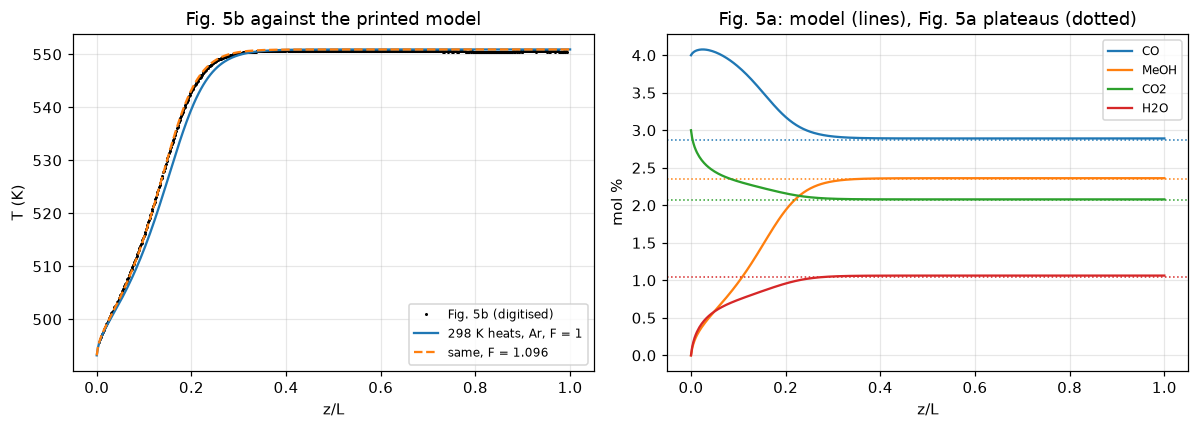

**Plateau.** With 298 K heats and argon the bed ends at 550.92 K, +0.33 K from Fig. 5b's 550.59 K (one pixel is 0.18 K). The van 't Hoff heats end +2.62 K from it, nitrogen with 298 K heats -0.44 K. A test free of any heat or heat capacity: at 50 bar the equilibrium composition of this feed is a function of T alone, so Fig. 5a's plateau composition must be at equilibrium at Fig. 5b's plateau temperature. With the printed $K_1^*$ it is at equilibrium at 551.6 K, with $K_3^*$ at 549.9 K, on either side of the figure's plateau temperature: the figure's plateau is, within these readings, the equilibrium of the printed constants.

**Shape.** At $F$ = 1 the RMS against Fig. 5b is 1.43 K; the bed heats up later than the figure (half rise at $z/L$ = 0.135 against the figure's 0.121). The factor that matches Fig. 5b best is $F$ = 1.096 (RMS 0.31 K, half rise 0.123). The RWGS reverses at 2.89 mm, as the text's "3 mm". The text's "3 cm" is not what Fig. 5b shows: there ($z/L$ = 0.2) the figure is 7.7 K below its own plateau; the model is within 0.5 K of its plateau only from $z/L$ = 0.329.

**Is F different from 1?** The rounding of every printed input $F$ depends on (Table 2's A and B, $m$, $W$) moves it by at most 0.0288. The unprinted thermodynamics move it more: heat capacities 3 % lower or higher give $F$ = 1.046 and 1.145, the methanol formation enthalpy within its NIST uncertainty 1.078 to 1.114. The largest shift, 0.050, is 1.05 times half the distance of $F$ from 1 (0.048). By the rule set before the run (no claim $F \ne 1$ when the thermodynamic shift exceeds half that distance) **$F$ is undecided**: Fig. 5b's shape depends as much on heat capacities the paper does not give as on the rate level. The ratio is close to 1, so the verdict rests on a thin margin and on the 3 % chosen for the heat capacities. Nitrogen as the inert needs $F$ = 1.363; the van 't Hoff heats leave an RMS of 2.22 K at their best $F$. The scaling shortcut agrees with a direct solve with the factor in the rates to 4e-12 K (bound 1e-6 K), and the pymrm profile meets that solve to 0.025 K.

In [8]:
N_BED = 1200          # cells over 2 bed lengths; quoted values from 1200 and 2400 cells
Z_MAX = 2.0
FIG5B = F5B[F5B.zL >= 0.01]
T_PLATEAU_FIG = RD[("5b", "base", "T_K")]


class Profile:
    """Adiabatic bed on two grids (n, 2n) over zeta in [0, z_max]; reads are Richardson-
    extrapolated. ``factor`` F reads the F = 1 solution at F zeta (exact scaling)."""

    def __init__(self, kin, th, T0=T0_BED, p=P_BED, y=Y_FEED, m=M_FLOW, w=W_BED, n=N_BED,
                 z_max=Z_MAX):
        self.T0, self.z_max = T0, z_max
        wf = w_over_f0(th, y, m, w)
        self.beds = [PlugFlowBed(kin, y, T0, p, wf, thermo=th, n=k * n, zeta_max=z_max).solve()
                     for k in (1, 2)]

    def u(self, z, F=1.0):
        z = np.asarray(z, dtype=float) * F
        return 2.0 * self.beds[1].at(z) - self.beds[0].at(z)

    def T(self, z, F=1.0):
        return self.T0 * self.u(z, F)[..., 6]

    def y(self, z, F=1.0):
        u = self.u(z, F)
        return u[..., :6] / u[..., :6].sum(axis=-1, keepdims=True)

    def rates(self, z, F=1.0):
        return F * self.beds[1].rates_at(self.u(z, F))

    def z_half(self, F=1.0, T_end=None):
        T_end = self.T(1.0, F) if T_end is None else T_end
        return one_root(lambda z: self.T(z, F) - 0.5 * (self.T0 + T_end), 0.0, 1.0, "half rise")

    def z_rev(self, F=1.0):
        return one_root(lambda z: self.rates(z, F)[1], 1e-5, 0.5, "RWGS reversal")


def rms_fig5b(prof, F, shift=0.0):
    return float(np.sqrt(np.mean((prof.T(FIG5B.zL.values, F) - FIG5B.T_K.values - shift) ** 2)))


def fit_F(prof, shift=0.0):
    return bounded_min(lambda F: rms_fig5b(prof, F, shift), 0.5, Z_MAX, n_scan=76)


def study_r3(par=PAR, heats="H298", inert="Ar", cp_scale=1.0, dhf=DHF_MEOH, T0=T0_BED,
             m=M_FLOW, w=W_BED, shift=0.0, equil=EQ, n=N_BED, tag=""):
    """Fig. 5 for one reading; ``shift`` moves the digitised Fig. 5b (a calibration defect)."""
    prof = Profile(kinetics(par, equil=equil), thermo(heats, inert, cp_scale, dhf=dhf), T0=T0,
                   m=m, w=w, n=n)
    F, rms_F = fit_F(prof, shift)
    out = {f"r3_T_plateau{tag}": prof.T(1.0), f"r3_rms_F1{tag}": rms_fig5b(prof, 1.0, shift),
           f"r3_F{tag}": F, f"r3_rms_F{tag}": rms_F}
    if tag == "":
        out["r3_plateau_minus_fig"] = prof.T(1.0) - (T_PLATEAU_FIG + shift)
        out["r3_zrev_mm"] = 1e3 * L_TUBE * prof.z_rev()
        out["r3_zhalf"] = prof.z_half()
        out["r3_zhalf_F"] = prof.z_half(F)
        T_end = prof.T(1.0)
        out["r3_z_within_halfK"] = one_root(lambda z: prof.T(z) - (T_end - 0.5), 0.0, 1.0,
                                            "0.5 K below the plateau")
        out["_prof"] = prof
    return out


R3 = study_r3()
PROF = R3.pop("_prof")
READINGS = {"_HvH_Ar": dict(heats="HvH", inert="Ar"), "_H298_N2": dict(heats="H298", inert="N2"),
            "_HvH_N2": dict(heats="HvH", inert="N2")}


def study_readings(**kw):
    out = {}
    for tag, rd in READINGS.items():
        out.update(study_r3(tag=tag, **rd, **kw))
    return out


R3.update(study_readings())

# the digitised Fig. 5b: its own half rise and its deficit at 3 cm
f5_T = lambda z, s=0.0: np.interp(z, F5B.zL, F5B.T_K) + s      # noqa: E731 (a data trace)


def study_fig5(shift=0.0, equil=EQ, l_tube=L_TUBE):
    """Readings of Fig. 5 alone: half rise, the 3 cm deficit, and the thermo-free plateau test."""
    Tp = T_PLATEAU_FIG + shift
    out = {"r3_fig_zhalf": one_root(lambda z: f5_T(z, shift) - 0.5 * (T0_BED + Tp),
                                    F5B.zL.min(), 1.0, "Fig. 5b half rise"),
           "r3_fig_deficit_3cm": Tp - f5_T(0.03 / l_tube, shift)}
    # Fig. 5a plateau composition at 50 bar: the T at which each reaction is at equilibrium
    y = 0.01 * np.array([RD[("5a", s, "y_molpct")] for s in ("CO", "CO2")])
    yM, yW = 0.01 * RD[("5a", "MeOH", "y_molpct")], 0.01 * RD[("5a", "H2O", "y_molpct")]
    # the rest is H2 and inert; carbon (CO + CO2 + MeOH = 0.07 of the feed) gives F/F0,
    # and the inert is conserved
    f_ratio = 0.07 / (y[0] + y[1] + yM)
    yI = Y_FEED[5] / f_ratio
    yH2 = 1.0 - y.sum() - yM - yW - yI
    q1 = yW * yM / (yH2 ** 3 * y[1] * P_BED ** 2)
    q3 = y[1] * yH2 / (y[0] * yW)                  # 1/K3* at equilibrium
    out["r3_T_from_K1_fig5a"] = equil["K1_slope"] / (np.log10(q1) - equil["K1_icpt"])
    out["r3_T_from_K3_fig5a"] = equil["K3inv_slope"] / (np.log10(1.0 / q3) - equil["K3inv_icpt"])
    out["r4_fig7a_minus_fig5b"] = RD[("7a", "220 C", "T_C")] + 273.15 - Tp
    return out


R3.update(study_fig5())
R4_FIG = {"r4_fig7a_minus_fig5b": R3.pop("r4_fig7a_minus_fig5b")}

# F against the rounding of every printed input it depends on, and against the thermodynamics
F0_ = R3["r3_F"]


def f_band(half_b=0.5, digits=3):
    """Linearised interval of F over the rounding of Table 2 (A to ``digits`` figures, B to
    ``half_b`` J/mol), m (2.8e-5 kg/s) and W (34.8 g); F scales exactly with m/W."""
    band = {"m and W": F0_ * (0.05 / 2.8 + 0.05 / 34.8)}
    for key in ("k5", "k1", "sqrtKH2", "KH2O"):
        a = PAR["A_" + key]
        half = 0.5 * 10.0 ** (np.floor(np.log10(abs(a))) - (digits - 1))
        band["A_" + key] = abs(study_r3(par=dict(PAR, **{"A_" + key: a + half}))["r3_F"] - F0_)
        band["B_" + key] = abs(study_r3(par=dict(PAR, **{"B_" + key: PAR["B_" + key] + half_b}))
                               ["r3_F"] - F0_)
    return {"r3_F_band": sum(band.values())}


def f_sens(cp_rel=0.03, dhf_u=DHF_MEOH_U):
    """F under heat capacities scaled by 1 -/+ cp_rel and the methanol enthalpy -/+ dhf_u."""
    sens = {f"Cp x {1 - cp_rel:.2f}": study_r3(cp_scale=1 - cp_rel)["r3_F"],
            f"Cp x {1 + cp_rel:.2f}": study_r3(cp_scale=1 + cp_rel)["r3_F"],
            "dHf(MeOH) low": study_r3(dhf=DHF_MEOH - dhf_u)["r3_F"],
            "dHf(MeOH) high": study_r3(dhf=DHF_MEOH + dhf_u)["r3_F"]}
    shift = max(abs(v - F0_) for v in sens.values())
    return {"r3_F_thermo_shift": shift, "r3_shift_over_half_distance": shift / (abs(F0_ - 1.0) / 2.0),
            "_sens": sens}


R3.update(f_band())
_fs = f_sens()
SENS = _fs.pop("_sens")
R3.update(_fs)

# the scaling shortcut against a direct solve with the factor in the rates (solve_ivp)
_refs = {}


def study_scaling(F_direct=None, n=N_BED):
    F_direct = F0_ if F_direct is None else F_direct
    th = thermo()
    if "one" not in _refs:
        _refs["one"] = reference_solution(PlugFlowBed(kinetics(), Y_FEED, T0_BED, P_BED,
                                                      w_over_f0(th), thermo=th), zeta_end=F0_)
    if F_direct not in _refs:
        _refs[F_direct] = reference_solution(PlugFlowBed(kinetics(factor=F_direct), Y_FEED, T0_BED,
                                                         P_BED, w_over_f0(th), thermo=th))
    ref1, refF = _refs["one"], _refs[F_direct]
    prof = PROF if n == N_BED else Profile(kinetics(), th, n=n)
    zz = np.linspace(0.0, 1.0, 41)
    return {"r3_scaling_gap_K": T0_BED * float(np.max(np.abs(ref1.sol(F0_ * zz)[6] - refF.sol(zz)[6]))),
            "r3_pymrm_vs_ivp_K": T0_BED * float(np.max(np.abs(prof.u(zz, F0_)[:, 6] - refF.sol(zz)[6])))}


R3.update(study_scaling())

tab = pd.DataFrame([{"reading": lab, "plateau (K)": R3[f"r3_T_plateau{t}"],
                     "plateau - Fig. 5b (K)": R3[f"r3_T_plateau{t}"] - T_PLATEAU_FIG,
                     "RMS at F = 1 (K)": R3[f"r3_rms_F1{t}"], "fitted F": R3[f"r3_F{t}"],
                     "RMS at F (K)": R3[f"r3_rms_F{t}"]}
                    for t, lab in (("", "298 K heats, Ar (page)"), ("_HvH_Ar", "van 't Hoff, Ar"),
                                   ("_H298_N2", "298 K heats, N2"), ("_HvH_N2", "van 't Hoff, N2"))])
show(tab, "c25r3", {c: "{:.3f}" for c in tab.columns[1:]})

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
zz = np.linspace(0.0, 1.0, 401)
ax[0].plot(F5B.zL, F5B.T_K, "k.", ms=2, label="Fig. 5b (digitised)")
ax[0].plot(zz, PROF.T(zz), label="298 K heats, Ar, F = 1")
ax[0].plot(zz, PROF.T(zz, F0_), "--", label=f"same, F = {F0_:.3f}")
ax[0].set(xlabel="z/L", ylabel="T (K)", title="Fig. 5b against the printed model")
ax[0].legend(fontsize=8)
for j, (s, lab) in enumerate((("CO", "CO"), ("MeOH", "MeOH"), ("CO2", "CO2"), ("H2O", "H2O"))):
    k = ["CO", "CO2", "H2", "MeOH", "H2O"].index(s)
    ax[1].plot(zz, 100 * PROF.y(zz)[:, k], color=f"C{j}", label=lab)
    ax[1].axhline(RD[("5a", s, "y_molpct")], color=f"C{j}", ls=":", lw=1)
ax[1].set(xlabel="z/L", ylabel="mol %", title="Fig. 5a: model (lines), Fig. 5a plateaus (dotted)")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Plateau.** With 298 K heats and argon the bed ends at {R3['r3_T_plateau']:.2f} K, "
    f"{R3['r3_plateau_minus_fig']:+.2f} K from Fig. 5b's {T_PLATEAU_FIG:.2f} K (one pixel is "
    f"{PX['5b']:.2f} K). The van 't Hoff heats end {R3['r3_T_plateau_HvH_Ar'] - T_PLATEAU_FIG:+.2f} K "
    f"from it, nitrogen with 298 K heats {R3['r3_T_plateau_H298_N2'] - T_PLATEAU_FIG:+.2f} K. A "
    "test free of any heat or heat capacity: at 50 bar the equilibrium composition of this feed is "
    "a function of T alone, so Fig. 5a's plateau composition must be at equilibrium at Fig. 5b's "
    f"plateau temperature. With the printed $K_1^*$ it is at equilibrium at "
    f"{R3['r3_T_from_K1_fig5a']:.1f} K, with $K_3^*$ at {R3['r3_T_from_K3_fig5a']:.1f} K, on "
    "either side of the figure's plateau temperature: the figure's plateau is, within these "
    "readings, the equilibrium of the printed constants.\n\n"
    f"**Shape.** At $F$ = 1 the RMS against Fig. 5b is {R3['r3_rms_F1']:.2f} K; the bed heats up "
    f"later than the figure (half rise at $z/L$ = {R3['r3_zhalf']:.3f} against the figure's "
    f"{R3['r3_fig_zhalf']:.3f}). The factor that matches Fig. 5b best is $F$ = {F0_:.3f} (RMS "
    f"{R3['r3_rms_F']:.2f} K, half rise {R3['r3_zhalf_F']:.3f}). The RWGS reverses at "
    f"{R3['r3_zrev_mm']:.2f} mm, as the text's \"3 mm\". The text's \"3 cm\" is not what Fig. 5b "
    f"shows: there ($z/L$ = 0.2) the figure is {R3['r3_fig_deficit_3cm']:.1f} K below its own "
    f"plateau; the model is within 0.5 K of its plateau only from $z/L$ = "
    f"{R3['r3_z_within_halfK']:.3f}.\n\n"
    f"**Is F different from 1?** The rounding of every printed input $F$ depends on (Table 2's A "
    f"and B, $m$, $W$) moves it by at most {R3['r3_F_band']:.4f}. The unprinted thermodynamics "
    f"move it more: heat capacities 3 % lower or higher give $F$ = {SENS['Cp x 0.97']:.3f} and "
    f"{SENS['Cp x 1.03']:.3f}, the methanol formation enthalpy within its NIST uncertainty "
    f"{SENS['dHf(MeOH) low']:.3f} to {SENS['dHf(MeOH) high']:.3f}. The largest "
    f"shift, {R3['r3_F_thermo_shift']:.3f}, is "
    + f"{R3['r3_shift_over_half_distance']:.2f} times"
    + f" half the distance of $F$ from 1 ({abs(F0_ - 1) / 2:.3f}). "
    + ("By the rule set before the run (no claim $F \\ne 1$ when the thermodynamic shift exceeds "
       "half that distance) **$F$ is undecided**: Fig. 5b's shape depends as much on heat "
       "capacities the paper does not give as on the rate level. The ratio is close to 1, so the "
       "verdict rests on a thin margin and on the 3 % chosen for the heat capacities."
       if R3["r3_shift_over_half_distance"] > 1.0 else
       "$F$ differs from 1 by more than the thermodynamic readings move it.")
    + f" Nitrogen as the inert needs $F$ = {R3['r3_F_H298_N2']:.3f}; the van 't Hoff heats leave "
    f"an RMS of {R3['r3_rms_F_HvH_Ar']:.2f} K at their best $F$. The scaling shortcut agrees with "
    f"a direct solve with the factor in the rates to {R3['r3_scaling_gap_K']:.0e} K (bound 1e-6 K), "
    f"and the pymrm profile meets that solve to {R3['r3_pymrm_vs_ivp_K']:.3f} K."))

### R4. Figs. 6 and 7 predicted, not refitted

The same bed at 15 and 30 bar (Fig. 6) and at inlet temperatures of 180 to
280 °C (Fig. 7), with the page's reading (298 K heats, argon) and $F$ = 1;
the half rise of the 200 °C case also at the $F$ of R3.

In [9]:
FIG7_T = {"200 C": 473.15, "220 C": 493.15, "240 C": 513.15, "280 C": 553.15}


def study_r4(par=PAR, heats="H298", F=None, dT0=0.0, n=N_BED // 2, pressures=(15.0, 30.0)):
    F = R3["r3_F"] if F is None else F
    kin, th = kinetics(par), thermo(heats)
    out = {}
    for pb, fig_p in zip(pressures, (15, 30)):
        pr = Profile(kin, th, p=pb, n=n)
        tag = f"{fig_p}bar"
        out[f"r4_dT_fig6b_{tag}"] = pr.T(1.0) - RD[("6b", f"{fig_p} bar", "T_K")]
        out[f"r4_dyM_fig6a_{tag}"] = 100 * pr.y(1.0)[3] - RD[("6a", f"{fig_p} bar", "y_MeOH_molpct")]
        if fig_p == 15:
            # CO2 minimum: root of the analytic derivative of y_CO2 along the bed
            def dy_co2(z):
                u = pr.u(z)
                du = pr.beds[1].source(u[None, :])[0]
                tot, dtot = u[:6].sum(), du[:6].sum()
                return (du[1] * tot - u[1] * dtot) / tot ** 2
            zmin = one_root(dy_co2, 0.02, 0.6, "CO2 minimum")
            out["r4_co2_min_15bar"] = 100 * pr.y(zmin)[1]
            out["r4_co2_min_z_15bar"] = zmin
    offs, dyM = [], []
    for curve, T0 in FIG7_T.items():
        pr = Profile(kin, th, T0=T0 + dT0, n=n)
        offs.append(RD[("7a", curve, "T_C")] + 273.15 - pr.T(1.0))
        dyM.append(100 * pr.y(1.0)[3] - RD[("7b", curve, "y_MeOH_molpct")])
        if curve == "200 C":
            out["r4_zhalf_200C"] = pr.z_half()
            out["r4_zhalf_200C_F"] = pr.z_half(F)
            out["r4_dyM_fig7b_200C"] = dyM[-1]
    out["r4_fig7a_offset_min"], out["r4_fig7a_offset_max"] = min(offs), max(offs)
    out["r4_fig7b_dyM_maxabs"] = float(np.max(np.abs(dyM)))
    return out


R4 = {**study_r4(), **R4_FIG}
display(Markdown(
    f"**Fig. 6.** The plateaus at 15 and 30 bar are {R4['r4_dT_fig6b_15bar']:+.2f} and "
    f"{R4['r4_dT_fig6b_30bar']:+.2f} K from Fig. 6b and {R4['r4_dyM_fig6a_15bar']:+.3f} and "
    f"{R4['r4_dyM_fig6a_30bar']:+.3f} mol% methanol from Fig. 6a. At 15 bar CO2 passes a "
    f"minimum of {R4['r4_co2_min_15bar']:.3f} mol% at $z/L$ = {R4['r4_co2_min_z_15bar']:.3f}; "
    f"Fig. 6c shows {RD[('6c', '15 bar', 'y_CO2_min_molpct')]:.3f} mol% at "
    f"{RD[('6c', '15 bar', 'zL_at_y_CO2_min')]:.3f}.\n\n"
    f"**Fig. 7.** The methanol plateaus at 200 to 280 °C are within "
    f"{R4['r4_fig7b_dyM_maxabs']:.3f} mol% of Fig. 7b. Fig. 7a's temperatures are not: they lie "
    f"{R4['r4_fig7a_offset_min']:.1f} to {R4['r4_fig7a_offset_max']:.1f} K above the model's "
    f"plateaus, and Fig. 7a's 220 °C case, the base case of Fig. 5, sits "
    f"{R4['r4_fig7a_minus_fig5b']:.1f} K above Fig. 5b's plateau while Fig. 7b's methanol "
    "equals Fig. 5a's: Fig. 7a's temperature axis is offset, and Fig. 7a is compared only after "
    "removing that offset. The 200 °C bed ignites late: half rise at $z/L$ = "
    f"{R4['r4_zhalf_200C']:.3f} at $F$ = 1 and {R4['r4_zhalf_200C_F']:.3f} at the $F$ of R3."))

**Fig. 6.** The plateaus at 15 and 30 bar are +0.34 and +0.37 K from Fig. 6b and +0.019 and +0.014 mol% methanol from Fig. 6a. At 15 bar CO2 passes a minimum of 2.407 mol% at $z/L$ = 0.137; Fig. 6c shows 2.407 mol% at 0.112.

**Fig. 7.** The methanol plateaus at 200 to 280 °C are within 0.033 mol% of Fig. 7b. Fig. 7a's temperatures are not: they lie 2.8 to 3.7 K above the model's plateaus, and Fig. 7a's 220 °C case, the base case of Fig. 5, sits 3.3 K above Fig. 5b's plateau while Fig. 7b's methanol equals Fig. 5a's: Fig. 7a's temperature axis is offset, and Fig. 7a is compared only after removing that offset. The 200 °C bed ignites late: half rise at $z/L$ = 0.469 at $F$ = 1 and 0.428 at the $F$ of R3.

### R5. Fig. 8: Klier's maximum

Caption (p. 9): $y_{CO}/y_{CO_2}$ varied at $y_{H_2}$ = 0.7, $p_t$ = 75 bar,
$T$ = 250 °C; the line is "simulated using the current kinetic model". No
$W/F_0$ is given. First the equilibrium the paper's own $K$'s allow at the
caption condition, then the $(T, W/F_0)$ that reproduce the curve with eq. 3
(isothermal plug flow), then the explanation of p. 9 ("In terms of the present
work, the evolution is solely due to the changing oxygen (or water)
concentration in the system.") tested by removing the water terms.

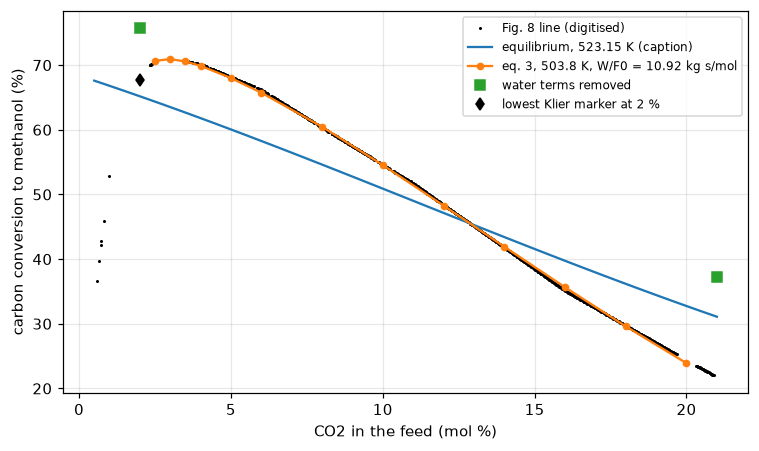

**Equilibrium at the caption.** 57 of 108 digitised points of the curve (every eighth column) lie above the equilibrium conversion of the paper's own $K_1^*$, $K_3^*$ at 523.15 K and 75 bar by more than three pixels (0.27 points); the curve exceeds it from $x$ = 1.96 to 12.90 % CO2, by up to 8.33 points. Klier's lowest marker at 2 % is 2.45 points above it too. No kinetic model can exceed equilibrium, so with these constants the curve cannot be at the caption's condition.

**What reproduces it.** Fitting $T$ and $W/F_0$ to the curve (13 points, $x$ = 2.5 to 20 %; below 2 % the drawn line is three steep chords between the authors' simulated points, which a smooth curve cannot follow) gives $T$ = 503.82 K and $W/F_0$ = 10.92 kg s/mol, RMS 0.28 points; at the caption's 523.15 K the best $W/F_0$ leaves 6.07 points. Which temperature the authors used is not printed.

**The p. 9 explanation by removal.** At the fitted point the equilibrium alone decreases with $x$ (0 increases on 10 points from 0.5 to 21 %): it has no maximum. With $K_{H_2O}$ and $K_{H_2O}/(K_8K_9K_{H_2})$ set to zero the conversion is 42.2 % at 0.5 %, 75.7 % at 2 % and 37.2 % at 21 % (equilibrium 37.2 %, full model 21.2 %): without the water terms the maximum remains, while at high CO2 the conversion climbs to equilibrium. So, at this point, the steep fall at high $x$ goes with the water terms of eq. 3 and the rise at low $x$ does not. At $x$ = 0 both rates are exactly zero (largest 0e+00): the model cannot produce the nonzero conversion Klier's marker at 0 % CO2 shows.

In [10]:
T_CAPTION, P8 = 523.15, 75.0
# x used in the fit (%): from 2.5 %, where the drawn line's chords between the authors'
# simulated points (kinks at about 3, 4, 6 and 16 %) follow the model's curvature; below 2 % the
# line is three steep chords (about 0.5, 1 and 2 %) that a smooth curve cannot follow
X_FIT = np.array([2.5, 3.0, 3.5, 4.0, 5.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 18.0, 20.0])
TAU_MAX, N8 = 40.0, 150
_cache8 = {}


def fig8_curve(x, shift=0.0):
    return np.interp(x, F8.x_CO2_pct, F8.X_MeOH_pct) + shift


def X_profile(kin, T, x, n=N8):
    """Carbon conversion to methanol (%) along an isothermal bed to W/F0 = TAU_MAX, Richardson
    from n and 2n cells; solves cached by kinetics, T and x."""
    key = (repr(sorted(kin.par.items())), repr(sorted(kin.equil.items())), tuple(sorted(kin.drop)),
           round(T, 9), x, n)
    if key not in _cache8:
        _cache8[key] = [PlugFlowBed(kin, fig8_feed(x), T, P8, TAU_MAX, n=k * n).solve()
                        for k in (1, 2)]
    b = _cache8[key]
    return lambda tau: 100 * (2 * b[1].at(tau / TAU_MAX)[..., 3] - b[0].at(tau / TAU_MAX)[..., 3]) / 0.30


def X_eq(kin, T, x, p=P8, shift=True):
    return 100 * equilibrium(kin, fig8_feed(x), T, p, shift=shift)["a"] / 0.30


X_GRID = np.array([0.5, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0, 16.0, 21.0])


def study_r5(par=PAR, T_fix=None, shift=0.0, p=P8, equil=EQ, drop=("KH2O", "Kw"), fit=True,
             eq_shift=True, t_caption=T_CAPTION):
    kin = kinetics(par, equil=equil)
    out = {}
    xs, Xs = F8.x_CO2_pct.values[::8], F8.X_MeOH_pct.values[::8] + shift
    exc = np.array([X - X_eq(kin, T_CAPTION, x, p) for x, X in zip(xs, Xs)])
    out["r5_points_above_eq"] = int(np.sum(exc > 3 * PX["8"]))
    out["_exc"], out["_xs"] = exc, xs
    out["r5_excess_max"] = float(exc.max())
    g = lambda x: fig8_curve(x, shift) - X_eq(kin, T_CAPTION, x, p)    # noqa: E731
    roots = find_roots(g, 0.8, 20.8, n_scan=40, xtol=1e-6)["roots"]
    out["r5_excess_x_lo"], out["r5_excess_x_hi"] = (roots[0], roots[-1]) if len(roots) == 2 \
        else (np.nan, np.nan)
    out["r5_klier_low_minus_eq"] = RD[("8", "Klier 2 %", "X_lowest_marker_pct")] + shift \
        - X_eq(kin, T_CAPTION, 2.0, p)
    target = fig8_curve(X_FIT, shift)

    def best_tau(T, at_end_ok=True):
        prof = [X_profile(kin, T, x) for x in X_FIT]
        f = lambda tau: float(np.sqrt(np.mean((np.array([pr(tau) for pr in prof]) - target) ** 2)))  # noqa: E731
        return bounded_min(f, 0.5, TAU_MAX, n_scan=40, xtol=1e-5, at_end_ok=at_end_ok)

    out["r5_rms_caption"] = best_tau(t_caption)[1]
    if fit:
        T_fit = bounded_min(lambda T: best_tau(T)[1], 483.15, 528.15, n_scan=7, xtol=2e-2)[0] \
            if T_fix is None else T_fix
        tau_fit, rms = best_tau(T_fit, at_end_ok=False)
        out.update({"r5_T_fit": T_fit, "r5_tau_fit": tau_fit, "r5_rms_fit": rms})
        out["_X_fit"] = [X_profile(kin, T_fit, x)(tau_fit) for x in X_FIT]
    else:
        T_fit, tau_fit = R5["r5_T_fit"], R5["r5_tau_fit"]
    # the p. 9 explanation by removal, at the fitted point
    eq_fit = np.array([X_eq(kin, T_fit, x, shift=eq_shift) for x in X_GRID])
    out["_eq_diff"] = np.diff(eq_fit)
    out["r5_eq_increases"] = int(np.sum(out["_eq_diff"] > 0))
    kin_dry = kinetics(par, equil=equil, drop=drop)
    out["r5_removed_X05"] = X_profile(kin_dry, T_fit, 0.5)(tau_fit)
    out["r5_removed_X2"] = X_profile(kin_dry, T_fit, 2.0)(tau_fit)
    out["r5_removed_X21"] = X_profile(kin_dry, T_fit, 21.0)(tau_fit)
    out["r5_model_X21"] = X_profile(kin, T_fit, 21.0)(tau_fit)
    out["r5_eq_X21"] = X_eq(kin, T_fit, 21.0)
    out["r5_rates_x0"] = float(np.abs(kin.rates(P8 * fig8_feed(0.0), T_fit)).max())
    return out


R5 = study_r5()
kin_p = kinetics()
T_FIT, TAU_FIT = R5["r5_T_fit"], R5["r5_tau_fit"]
n_above = R5["r5_points_above_eq"]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(F8.x_CO2_pct, F8.X_MeOH_pct, "k.", ms=2, label="Fig. 8 line (digitised)")
xe = np.linspace(0.5, 21.0, 60)
ax.plot(xe, [X_eq(kin_p, T_CAPTION, x) for x in xe], label="equilibrium, 523.15 K (caption)")
ax.plot(X_FIT, R5["_X_fit"], "o-", ms=4, label=f"eq. 3, {T_FIT:.1f} K, W/F0 = {TAU_FIT:.2f} kg s/mol")
ax.plot([2.0, 21.0], [R5["r5_removed_X2"], R5["r5_removed_X21"]], "s", label="water terms removed")
ax.errorbar([2.0], [RD[("8", "Klier 2 %", "X_lowest_marker_pct")]], fmt="kd", ms=6,
            label="lowest Klier marker at 2 %")
ax.set(xlabel="CO2 in the feed (mol %)", ylabel="carbon conversion to methanol (%)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Equilibrium at the caption.** {n_above} of {len(R5['_xs'])} digitised points of the curve "
    f"(every eighth column) lie above the equilibrium conversion of the paper's own $K_1^*$, "
    f"$K_3^*$ at 523.15 K and 75 bar by more than three pixels ({3 * PX['8']:.2f} points); the "
    f"curve exceeds it from $x$ = {R5['r5_excess_x_lo']:.2f} to {R5['r5_excess_x_hi']:.2f} % CO2, "
    f"by up to {R5['r5_excess_max']:.2f} points. Klier's lowest marker at 2 % is "
    f"{R5['r5_klier_low_minus_eq']:.2f} points above it too. No kinetic model can exceed "
    "equilibrium, so with these constants the curve cannot be at the caption's condition.\n\n"
    f"**What reproduces it.** Fitting $T$ and $W/F_0$ to the curve ({len(X_FIT)} points, "
    f"$x$ = 2.5 to 20 %; below 2 % the drawn line is three steep chords between the authors' "
    f"simulated points, which a smooth curve cannot follow) gives $T$ = {T_FIT:.2f} K and $W/F_0$ = {TAU_FIT:.2f} kg s/mol, RMS "
    f"{R5['r5_rms_fit']:.2f} points; at the caption's 523.15 K the best $W/F_0$ leaves "
    f"{R5['r5_rms_caption']:.2f} points. Which temperature the authors used is not printed.\n\n"
    f"**The p. 9 explanation by removal.** At the fitted point the equilibrium alone decreases "
    f"with $x$ ({R5['r5_eq_increases']} increases on {len(X_GRID)} points from 0.5 to 21 %): it "
    f"has no maximum. With $K_{{H_2O}}$ and $K_{{H_2O}}/(K_8K_9K_{{H_2}})$ set to zero the "
    f"conversion is {R5['r5_removed_X05']:.1f} % at 0.5 %, {R5['r5_removed_X2']:.1f} % at 2 % and "
    f"{R5['r5_removed_X21']:.1f} % at 21 % "
    f"(equilibrium {R5['r5_eq_X21']:.1f} %, full model {R5['r5_model_X21']:.1f} %): without the "
    "water terms the maximum remains, while at high CO2 the conversion climbs to equilibrium. "
    "So, at this point, the steep fall at high $x$ goes with the water terms of eq. 3 and the "
    "rise at low $x$ does not. At $x$ = 0 both rates "
    f"are exactly zero (largest {R5['r5_rates_x0']:.0e}): the model cannot produce the nonzero "
    "conversion Klier's marker at 0 % CO2 shows."))

## Validation

The checks below use no figure data.

- **V1, element balances.** C, H and O flows at every cell of the pymrm solution and at the
  solve_ivp nodes equal the feed's.
- **V2, the test energy model.** With a constant $c_p$ the adiabatic bed has an exact
  invariant $T - T_0 = \sum_j(-\Delta H_j)\xi_j/(m c_p)$; it holds at every cell, a long bed
  ends on the algebraic adiabatic equilibrium (two-reaction equilibrium on the invariant), and
  both reactions are at equilibrium there.
- **V3, convergence.** $T(z/L = 0.1)$, the half rise and the RWGS reversal on 250 to 8000
  cells: observed orders of first-order upwind, the Richardson values against the
  check values of the independent script.

In [11]:
LADDER = (250, 500, 1000, 2000, 4000, 8000)


def study_v(ladder=LADDER, nu=NU, cp_solve=CP_TEST, factor=1.0, z_long=5.0, ratio=None,
            maxfev=60, orders=True):
    kin = kinetics(factor=factor)
    th_inv = thermo("HvH", cp_mass=CP_TEST)
    th_solve = thermo("HvH", cp_mass=cp_solve)
    wf = w_over_f0(th_inv)
    out = {}
    bed = PlugFlowBed(kin, Y_FEED, T0_BED, P_BED, wf, thermo=th_solve, n=2000, nu=nu).solve(
        maxfev=maxfev, strict=maxfev >= 60)
    u = bed.u
    out["v1_balance_pymrm"] = float(np.abs((u[:, :6] - bed.u_in[:6]) @ ATOMS.T).max())
    sol = reference_solution(bed)
    out["v1_balance_ivp"] = float(np.abs((sol.y[:6].T - bed.u_in[:6]) @ ATOMS.T).max())
    xi = np.stack([u[:, 3] - Y_FEED[3], u[:, 0] - Y_FEED[0]], axis=-1)
    m_feed = th_inv.m_feed_of(Y_FEED)
    inv = T0_BED * u[:, 6] - T0_BED - xi @ (-th_inv.dH) / (m_feed * CP_TEST)
    out["v2_invariant_K"] = float(np.abs(inv).max())
    out["v_backward_error"] = float(bed.backward_error())
    eq = adiabatic_equilibrium(kin, th_inv, Y_FEED, T0_BED, P_BED)
    long = PlugFlowBed(kin, Y_FEED, T0_BED, P_BED, wf, thermo=th_solve, n=2000,
                       zeta_max=z_long, nu=nu).solve()
    uo = long.outlet()
    out["v2_long_bed_minus_Teq_K"] = abs(T0_BED * uo[6] - eq["T"])
    p_out = P_BED * uo[:6] / uo[:6].sum()
    out["v2_ln_QK_max"] = float(np.abs(np.log(kin.approach(p_out, T0_BED * uo[6]))).max())

    def quantities(n):
        b = PlugFlowBed(kin, Y_FEED, T0_BED, P_BED, wf, thermo=th_solve, n=n, nu=nu).solve()
        return np.array([T0_BED * b.at(0.1)[6],
                         one_root(lambda z: T0_BED * b.at(z)[6] - 0.5 * (T0_BED + eq["T"]),
                                  0.0, 1.0, "half rise"),
                         one_root(lambda z: b.rates_at(b.at(z)[None, :])[0, 1], 1e-4, 0.5,
                                  "RWGS reversal")])
    if not orders:
        return out
    vals = np.array([quantities(n) for n in ladder])
    fin = np.abs(vals[-1] - vals[-2])
    out["v3_roundoff_ratio_min"] = float(np.min(fin / (ladder[-1] * np.finfo(float).eps
                                                       * np.abs(vals[-1]))))
    try:                              # one study per quantity, from the values above
        st = [observed_orders(lambda n, it=iter(vals[:, j]): next(it), ladder, ratio=ratio)
              for j in range(vals.shape[1])]
    except ValueError:
        return out
    orders = np.array([np.asarray(q["orders"], dtype=float) for q in st]).T   # (triples, 3)
    out["v3_order_finest_min"], out["v3_order_finest_max"] = float(orders[-1].min()), float(orders[-1].max())
    out["v3_orders_decreasing_steps"] = int(np.sum(np.diff(orders, axis=0) < 0))
    ref = np.array([CHECK["AD_T_at_zL0p1"], CHECK["AD_zL_T_half_rise"], CHECK["AD_zL_RWGS_reversal"]])
    err = np.array([float(q["error_estimate"]) for q in st])
    extr = np.array([float(q["extrapolated"]) for q in st])
    with np.errstate(all="ignore"):
        out["v3_richardson_gap_max"] = float(np.max(np.abs(extr - ref) / np.abs(err)))
    out["_st"] = {"values": vals, "orders": orders}
    return out


V = study_v()
ST = V.pop("_st")
_vals = np.asarray(ST["values"], dtype=float)
show(pd.DataFrame({"cells": LADDER, "T(z/L=0.1) (K)": _vals[:, 0], "half rise": _vals[:, 1],
                   "RWGS reversal": _vals[:, 2]}),
     "c25v3", {"T(z/L=0.1) (K)": "{:.6f}", "half rise": "{:.7f}", "RWGS reversal": "{:.7f}"})
show(pd.DataFrame({"triple": [f"{LADDER[k]} to {LADDER[k + 2]}" for k in range(len(LADDER) - 2)],
                   "order, T(z/L=0.1)": ST["orders"][:, 0], "order, half rise": ST["orders"][:, 1],
                   "order, RWGS reversal": ST["orders"][:, 2]}),
     "c25v3o", {c: "{:.3f}" for c in ("order, T(z/L=0.1)", "order, half rise", "order, RWGS reversal")})
display(Markdown(
    f"V1: the element balances close to {max(V['v1_balance_pymrm'], V['v1_balance_ivp']):.0e} "
    f"(bound 1e-12) on both routes. V2: the invariant holds to {V['v2_invariant_K']:.0e} K "
    f"(bound 1e-9 K) at every cell; a bed five times longer ends {V['v2_long_bed_minus_Teq_K']:.0e} K "
    f"from the algebraic adiabatic equilibrium (bound 1e-6 K), with both reactions at "
    f"equilibrium there ($|\\ln Q/K|$ {V['v2_ln_QK_max']:.0e}, bound 1e-6). Newton's backward "
    f"error is {V['v_backward_error']:.0e} (bound 1e-8). V3: the observed orders rise toward 1 "
    f"with refinement on all three quantities ({V['v3_orders_decreasing_steps']} decreases; the "
    "coarse grids are pre-asymptotic, the RWGS reversal sits within five cells of the inlet on "
    f"250 cells) and the finest triple gives {V['v3_order_finest_min']:.3f} to "
    f"{V['v3_order_finest_max']:.3f} (theory 1); the finest differences are at "
    f"least {V['v3_roundoff_ratio_min']:.0e} times round-off, and the Richardson values meet the "
    f"independent script's values within {V['v3_richardson_gap_max']:.2f} of their own error "
    "estimates (bound 1)."))

cells,T(z/L=0.1) (K),half rise,RWGS reversal
250,517.846380,0.1173910,0.0224350
500,518.008776,0.1169281,0.0209056
1000,518.122146,0.1165850,0.0200741
2000,518.190627,0.1163725,0.0196411
4000,518.228655,0.1162532,0.0194158
8000,518.248765,0.1161898,0.0193010


triple,"order, T(z/L=0.1)","order, half rise","order, RWGS reversal"
250 to 1000,0.518,0.432,0.879
500 to 2000,0.727,0.692,0.942
1000 to 4000,0.849,0.832,0.942
2000 to 8000,0.919,0.911,0.972


V1: the element balances close to 6e-15 (bound 1e-12) on both routes. V2: the invariant holds to 4e-12 K (bound 1e-9 K) at every cell; a bed five times longer ends 8e-12 K from the algebraic adiabatic equilibrium (bound 1e-6 K), with both reactions at equilibrium there ($|\ln Q/K|$ 1e-15, bound 1e-6). Newton's backward error is 2e-16 (bound 1e-8). V3: the observed orders rise toward 1 with refinement on all three quantities (0 decreases; the coarse grids are pre-asymptotic, the RWGS reversal sits within five cells of the inlet on 250 cells) and the finest triple gives 0.911 to 0.972 (theory 1); the finest differences are at least 2e+07 times round-off, and the Richardson values meet the independent script's values within 0.08 of their own error estimates (bound 1).

In [12]:
# Claims: every number the page states, with how it is checked.
# R1: closed forms of printed digits (deterministic; tight tolerances)
claims.count("r1_groups_outside_rounding", R1["r1_hu"], 1.0, min_margin=0.05,
             note="Table 1 converted with R = 8.314462618, half-units from Table 2")
claims.value("r1_hu_KH2O_R8314", R1_8314["r1_hu_KH2O"], rtol=1e-6, note="R = 8.314")
for k in ("r1_R_lo", "r1_R_hi", "r1_multiplier", "r1_tA_max_k5", "r1_tA_max_KH2O",
          "r1_tA_min_sqrtKH2", "r1_tA_min_k1", "r1_dS_H2_T2", "r1_voidage"):
    claims.value(k, R1[k], rtol=1e-9)
claims.exact("r1_dof", R1["r1_dof"])
claims.value("r1_t975", R1["r1_t975"], rtol=1e-6)
claims.bound("r1_t975_above_window", R1["r1_t975_above_window"], min=0.0, basis="theory",
             note="t(0.975, 543) minus the largest multiplier the printed digits allow")
claims.bound("r1_sd_gap", R1["r1_sd_gap"], min=0.0, basis="theory",
             note="lower end of the value/t window minus the printed sd 0.375")
claims.count("r1_A_not_significant", -R1["r1_tA_max"], -1.96, min_margin=0.05,
             note="frequency factors with t(A) below 1.96 for every correlation")
claims.bound("r1_dS_H2_T2_hu", R1["r1_dS_H2_T2_hu"], max=1.0, basis="theory")
claims.bound("r1_dS_H2_T1_hu", R1["r1_dS_H2_T1_hu"], min=1.0, basis="theory")
claims.bound("r1_dS_H2O_hu", R1["r1_dS_H2O_hu"], max=1.0, basis="theory")
claims.says("8.31413", "r1_R_lo")                     # Parameters and assumptions
claims.says("8.31463", "r1_R_hi")
# R2
for k in R2:
    claims.value(k, R2[k], rtol=1e-9)
# R3: profiles on 1500 and 3000 cells, Richardson; tolerances above the grid effects
claims.value("r3_T_plateau", R3["r3_T_plateau"], rtol=1e-5, unit="K")
claims.value("r3_plateau_minus_fig", R3["r3_plateau_minus_fig"], atol=0.05, rtol=0.0, unit="K")
for t in READINGS:
    claims.value(f"r3_T_plateau{t}", R3[f"r3_T_plateau{t}"], rtol=1e-5, unit="K")
    claims.value(f"r3_F{t}", R3[f"r3_F{t}"], rtol=2e-3)
for t in ("", "_HvH_Ar"):
    claims.value(f"r3_rms_F1{t}", R3[f"r3_rms_F1{t}"], rtol=0.02, unit="K")
    claims.value(f"r3_rms_F{t}", R3[f"r3_rms_F{t}"], rtol=0.02, unit="K")
claims.value("r3_F", R3["r3_F"], rtol=2e-3)
for k in ("r3_zrev_mm", "r3_zhalf", "r3_zhalf_F", "r3_z_within_halfK", "r3_fig_zhalf",
          "r3_fig_deficit_3cm", "r3_T_from_K1_fig5a", "r3_T_from_K3_fig5a"):
    claims.value(k, R3[k], rtol=2e-3)
claims.value("r3_F_band", R3["r3_F_band"], rtol=0.05)
claims.value("r3_F_thermo_shift", R3["r3_F_thermo_shift"], rtol=0.05)
claims.value("r3_shift_over_half_distance", R3["r3_shift_over_half_distance"], rtol=0.01,
             note="largest thermodynamic shift of F over |F - 1|/2 (the plan's stop rule)")
claims.bound("r3_scaling_gap_K", R3["r3_scaling_gap_K"], max=1e-6, basis="tolerance",
             note="solve_ivp rtol 1e-12 on both routes")
claims.bound("r3_pymrm_vs_ivp_K", R3["r3_pymrm_vs_ivp_K"], max=0.05, basis="chosen",
             note="Richardson from 1200 and 2400 cells against Radau")
# R4
for k in R4:
    tol = 0.005 if ("dyM" in k or k == "r4_co2_min_15bar") else \
        0.002 if ("zhalf" in k or k == "r4_co2_min_z_15bar") else 0.05
    claims.value(k, R4[k], rtol=0.0, atol=tol)
# R5
claims.count("r5_points_above_eq", R5["_exc"], 3 * PX["8"], min_margin=1e-4,
             note="digitised points above the caption equilibrium by three pixels")
claims.count("r5_eq_increases", R5["_eq_diff"], 0.0, min_margin=1e-6,
             note="increases of the equilibrium conversion with x at the fitted T")
for k in ("r5_excess_max", "r5_excess_x_lo", "r5_excess_x_hi", "r5_klier_low_minus_eq",
          "r5_T_fit", "r5_tau_fit", "r5_rms_fit", "r5_rms_caption", "r5_removed_X05", "r5_removed_X2",
          "r5_removed_X21", "r5_model_X21", "r5_eq_X21"):
    claims.value(k, R5[k], rtol=0.01)
claims.bound("r5_rates_x0", R5["r5_rates_x0"], max=0.0, basis="identity", structural=True,
             note="r = 0 exactly at p_CO2 = p_H2O = 0 (multiplied-out approach terms)")
# Validation
claims.bound("v1_balance_pymrm", V["v1_balance_pymrm"], max=1e-12, basis="identity")
claims.bound("v1_balance_ivp", V["v1_balance_ivp"], max=1e-12, basis="identity")
claims.bound("v2_invariant_K", V["v2_invariant_K"], max=1e-9, basis="tolerance")
claims.bound("v2_long_bed_minus_Teq_K", V["v2_long_bed_minus_Teq_K"], max=1e-6, basis="tolerance")
claims.bound("v2_ln_QK_max", V["v2_ln_QK_max"], max=1e-6, basis="tolerance")
claims.bound("v_backward_error", V["v_backward_error"], max=1e-8, basis="tolerance")
claims.bound("v3_order_finest_min", V["v3_order_finest_min"], min=0.9, max=1.1, basis="theory")
claims.bound("v3_order_finest_max", V["v3_order_finest_max"], min=0.9, max=1.1, basis="theory")
claims.exact("v3_orders_decreasing_steps", V["v3_orders_decreasing_steps"])
claims.bound("v3_roundoff_ratio_min", V["v3_roundoff_ratio_min"], min=1e3, basis="theory")
claims.bound("v3_richardson_gap_max", V["v3_richardson_gap_max"], max=1.0, basis="theory")

### The break table

Each row injects one defect through an argument of the studies above and
records the claims it moves; a claim is caught when its own check fails.

In [13]:
def edit(df, group, param, col, new):
    out = df.copy()
    out.loc[(out.group == group) & (out.param == param), col] = new
    return out


def bad_nu():
    nu = NU.copy()
    nu[4, 1] = 2.0           # RWGS producing two water
    return nu


ROWS = [
    ("gas constant 8.314", lambda: study_r1(r_gas=8.314)),
    ("T_av read as 501.75 K", lambda: study_r1(t_av=501.75)),
    ("Table 1 B of K_H2O read 124,191", lambda: {
        **study_r1(t1=edit(T1, "K_H2O", "B", "value", "124191")),
        "r1_hu_KH2O_R8314": study_r1(t1=edit(T1, "K_H2O", "B", "value", "124191"),
                                     r_gas=8.314)["r1_hu_KH2O"]}),
    ("normal quantile instead of t(543)", lambda: study_r1(quantile="normal")),
    ("276 experiments counted as one response each", lambda: study_r1(n_exp=138)),
    ("Table 1 sd of sqrt(K_H2) A* read 0.376",
     lambda: study_r1(t1=edit(T1, "sqrt(K_H2)", "A*", "std_dev", "0.376"))),
    ("Table 1 sd of the k5-lump B read 610.28",
     lambda: study_r1(t1=edit(T1, "k'5a K'2 K3 K4 K_H2", "B", "std_dev", "610.28"))),
    ("Table 1 sd of the k'1 B read 16940",
     lambda: study_r1(t1=edit(T1, "k'1", "B", "std_dev", "16940"))),
    ("Table 2 sqrt(K_H2) A read 0.449",
     lambda: study_r1(t2=edit(T2, "sqrt(K_H2)", "A", "value_printed", "0.449"))),
    ("Table 1 sqrt(K_H2) A* read 30.83",
     lambda: study_r1(t1=edit(T1, "sqrt(K_H2)", "A*", "value", "30.83"))),
    ("Table 2 K_H2O A read 6.62e-10",
     lambda: study_r1(t2=edit(T2, "K_H2O", "A", "value_printed", "6.62e-10"))),
    ("Table 3 catalyst density read 1575", lambda: {"r1_voidage": 1.0 - W_BED / (
        1575.0 * np.pi / 4.0 * D_TUBE ** 2 * L_TUBE)}),
    ("pressures in kPa in the kinetic groups", lambda: study_r2(p_unit=0.01)),
    ("Table 2 k5-lump A 10 % high", lambda: {**study_r2(par=dict(PAR, A_k5=1.1 * PAR["A_k5"])),
                                              **study_r3(par=dict(PAR, A_k5=1.1 * PAR["A_k5"]))}),
    ("Table 2 B of K_H2O read 142,119", lambda: study_r2(par=dict(PAR, B_KH2O=142119.0))),
    ("van 't Hoff heats instead of 298 K heats",
     lambda: {**study_r3(heats="HvH"), **study_r4(heats="HvH")}),
    ("inert N2 instead of Ar", lambda: study_r3(inert="N2")),
    ("Table 3 inlet temperature read 498.2 K", lambda: {**study_r3(T0=498.2),
                                                        **study_readings(T0=498.2)}),
    ("Table 3 catalyst mass read 38.4 g", lambda: study_r3(w=0.0384)),
    ("heat capacities 10 % high", lambda: study_r3(cp_scale=1.1)),
    ("Fig. 5 calibration 1 K low", lambda: {**study_r3(shift=-1.0), **study_fig5(shift=-1.0)}),
    ("K1* intercept read -10.529", lambda: {**study_fig5(equil=dict(EQ, K1_icpt=-10.529)),
                                            **study_r3(equil=dict(EQ, K1_icpt=-10.529))}),
    ("K3* intercept read 2.092", lambda: study_fig5(equil=dict(EQ, K3inv_icpt=2.092))),
    ("Fig. 7 inlet temperatures 5 K low", lambda: study_r4(dT0=-5.0)),
    ("rate factor 1 in the 200 C prediction", lambda: study_r4(F=1.0)),
    ("Fig. 8 at its caption temperature (W/F0 fitted alone)", lambda: study_r5(T_fix=T_CAPTION)),
    ("Fig. 8 calibration 2 points high", lambda: study_r5(shift=2.0, fit=False)),
    ("RWGS frozen in the equilibrium", lambda: study_r5(eq_shift=False, fit=False)),
    ("Fig. 8 caption temperature read as 260 C", lambda: study_r5(t_caption=533.15, fit=False)),
    ("only K_H2O removed in the p. 9 test", lambda: study_r5(drop=("KH2O",), fit=False)),
    ("3 cm taken on a 0.10 m tube", lambda: study_fig5(l_tube=0.10)),
    ("direct solve with the factor 0.1 % high", lambda: study_scaling(F_direct=1.001 * F0_)),
    ("pymrm profile on 100 cells", lambda: study_scaling(n=100)),
    ("Fig. 6 low pressure read as 14 bar", lambda: study_r4(pressures=(14.0, 30.0))),
    ("Newton stopped after 2 iterations", lambda: study_v(maxfev=2, orders=False)),
    ("one grid of 1000 cells four times, declared a ladder of ratio 2",
     lambda: study_v(ladder=(1000,) * 4, ratio=2.0)),
    ("rounding of B taken as 50 J/mol", lambda: f_band(half_b=50.0)),
    ("heat capacities perturbed by 1 % instead of 3 %", lambda: f_sens(cp_rel=0.01)),
    ("RWGS producing two water", lambda: study_v(nu=bad_nu(), orders=False)),
    ("c_p in the solve 10 % below the invariant's",
     lambda: study_v(cp_solve=3015.0, orders=False)),
    ("bed of 0.05 W for the equilibrium plateau", lambda: study_v(z_long=0.05, orders=False)),
    ("pymrm rates 1 % high against the script's values", lambda: study_v(factor=1.01)),
    ("ladder on 10 to 320 cells", lambda: study_v(ladder=(10, 20, 40, 80, 160, 320))),
]
claims.define_rows([label for label, _ in ROWS])
BREAK, CRASHED = [], []
for label, run in ROWS:
    try:
        with np.errstate(all="ignore"):
            broken = run()
    except (ValueError, RuntimeError) as exc:
        CRASHED.append((label, str(exc)[:80]))
        continue
    for name, val in broken.items():
        if name not in claims.metrics or name.startswith("_"):
            continue
        if isinstance(val, (float, np.floating)) and not np.isfinite(val):
            continue                       # only finite values are recorded
        BREAK.append((label, name, claims.metrics[name]["value"], val,
                      claims.breaks(label, name, val)))
bt = pd.DataFrame(BREAK, columns=["injected defect", "claim", "clean", "with defect", "caught"])
caught = bt.groupby("claim").caught.any()
fmt = lambda v: f"{v:.4g}" if isinstance(v, (float, np.floating)) else str(v)  # noqa: E731
show(bt[bt.caught], "c25bt", {"clean": fmt, "with defect": fmt})
nonstruct = [k for k, c in claims.metrics.items() if not c.get("structural")]
print(f"{len(ROWS)} rows; claims caught by at least one row: "
      f"{sum(bool(caught.get(k, False)) for k in nonstruct)} of {len(nonstruct)} non-structural; "
      f"not caught: {sorted(k for k in nonstruct if not caught.get(k, False)) or 'none'}")
print("rows whose study raised (recorded nothing):", CRASHED or "none")

injected defect,claim,clean,with defect,caught
gas constant 8.314,r1_tA_max_k5,0.7009,0.7009,True
gas constant 8.314,r1_tA_max_KH2O,1.399,1.398,True
gas constant 8.314,r1_tA_min_sqrtKH2,2.178,2.178,True
gas constant 8.314,r1_tA_min_k1,2.39,2.39,True
gas constant 8.314,r1_dS_H2_T2,11.56,11.56,True
gas constant 8.314,r1_groups_outside_rounding,0,1,True
T_av read as 501.75 K,r1_R_lo,8.314,8.311,True
T_av read as 501.75 K,r1_R_hi,8.315,8.312,True
T_av read as 501.75 K,r1_tA_max_k5,0.7009,0.7012,True
T_av read as 501.75 K,r1_tA_max_KH2O,1.399,1.399,True


43 rows; claims caught by at least one row: 87 of 87 non-structural; not caught: none
rows whose study raised (recorded nothing): none


## What pymrm adds

The rate law and the statistics are plain numpy. pymrm contributes the
reactors: the adiabatic and the isothermal plug-flow beds as steady
finite-volume problems in the catalyst-mass coordinate
(`construct_convflux_upwind`, `construct_div`, a `NumJac` Jacobian, one
bounded `newton` solve per bed, checked by `residual_check`), `find_roots` for
the RWGS reversal, the half rise, the CO2 minimum and the crossings of Fig. 8,
and `observed_orders` for the convergence study. A `solve_ivp` march computes
the same beds and is the page's second route. With them the page finds what
the paper does not state: which unprinted thermodynamics its Fig. 5 used,
that Fig. 5b's shape cannot settle the rate level, that Fig. 7a's temperature
axis is offset, and that Fig. 8's curve exceeds the equilibrium of the paper's own
constants at its caption's condition.

## Reuse

- **Units and constants.** Pressures in bar, rates in mol/(kg$_\mathrm{cat}$ s),
  $B$ in J/mol with $R$ = 8.3145; the equilibrium constants of p. 5 (Graaf et
  al.), $K_3^*$ being the water gas shift constant. `Kinetics` takes Table 2 as
  one dictionary.
- **Thermodynamics are yours to supply.** The paper prints neither heats nor
  heat capacities; Fig. 5's plateau is reproduced by 298 K heats with argon,
  not by the van 't Hoff heats of the equilibrium correlations.
- **Do not tune the rates to the figures.** Fig. 5b's shape cannot fix the
  rate level: the factor it implies moves with the unprinted heat capacities
  about as much as it differs from 1 (R3), and Fig. 8's curve exceeds the
  equilibrium of the paper's constants at its caption's condition (R5).
- **Statistics.** Table 1's intervals use 1.96; the $k_5$-lump frequency
  factor is not significant once back-transformed.
- Related pages: `C2.1` (Xu and Froment steam reforming, the same LHHW
  formalism and a parity test this page cannot make), `C2.10` (cooled fixed
  bed), `C1.1` (LHHW forms). In the catalogue, not yet built: `D3.3` (the
  industrial methanol reactor) and `C2.4` (Graaf et al.'s kinetics with both
  CO and CO2 hydrogenation, the usual alternative).

In [14]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for C2.5:
  r1_groups_outside_rounding  = 0                exact  exact, margin 0.275
  r1_hu_KH2O_R8314            = 1.8071           value  rtol 1e-06
  r1_R_lo                     = 8.3141           value  rtol 1e-09
  r1_R_hi                     = 8.3146           value  rtol 1e-09
  r1_multiplier               = 1.96             value  rtol 1e-09
  r1_tA_max_k5                = 0.70094          value  rtol 1e-09
  r1_tA_max_KH2O              = 1.3985           value  rtol 1e-09
  r1_tA_min_sqrtKH2           = 2.178            value  rtol 1e-09
  r1_tA_min_k1                = 2.3905           value  rtol 1e-09
  r1_dS_H2_T2                 = 11.56            value  rtol 1e-09
  r1_voidage                  = 0.34993          value  rtol 1e-09
  r1_dof                      = 543              exact  exact
  r1_t975                     = 1.9643           value  rtol 1e-06
  r1_t975_above_window        = (here 4.2e-03)   bound  bound >= 0 [theory]
  r1_sd_gap                   = 